# 8. Estimating parameters

> Extend the estimation problem beyond position and velocity: estimate an SRP scale factor together with the state, or carry it as a consider parameter, and compare both with ignoring the error, over the tracking arc and past it.
>
> ⏱ ~15 min &nbsp;·&nbsp; **Prereqs:** [7. Sequential filtering & process noise](07_sequential_filtering.ipynb) &nbsp;·&nbsp; **Uses:** `outputs/02_truth_dynamics/truth.bsp`, `outputs/03_tracking_data/*.json` &nbsp;·&nbsp; **Next:** [9. Tracking data II: real DSN data](09_real_dsn_data.ipynb)

[Chapter 7](07_sequential_filtering.ipynb) used process noise to absorb a missing acceleration statistically. When the form of the error is known, it can instead be modeled: either estimated as part of the state, or carried as a known uncertainty. This chapter does both for solar radiation pressure, with the same week of simulated tracking as chapters 6 and 7.

## Setup

The scenario, the measurement models from [chapter 5](05_filter_measurements.ipynb), and the a-priori state from [chapter 4](04_filter_dynamics.ipynb). All of it comes from [`scenario.py`](scenario.py). Every run here uses a mis-sized filter spacecraft and its own state definition, which it passes to `reference_propagator()`.

**Starting here?** This chapter reads the outputs of chapters [2](02_truth_dynamics.ipynb) and [3](03_tracking_data.ipynb). Run `python prepare.py 08` from `tutorials/v2/` to generate them (about 15 s); the setup cell stops with a message if they are missing.

In [1]:
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scarabaeus as scb

from scenario import (
    km, m, minute, day, J2000,           # units, frame
    epochs, orex, mass, cr,              # tracking arc, truth spacecraft and its properties (ch. 1-2)
    models, TRACKING_DIR,                # measurement models (ch. 3)
    r_apriori, v_apriori, P0,            # the a-priori state and covariance (ch. 4)
    apriori_sigmas as sigma_apriori,
    reference_propagator,
)

out = Path("outputs/08_estimating_more")
shutil.rmtree(out, ignore_errors=True)
out.mkdir(parents=True)
tracking_dir = Path(TRACKING_DIR)  # produced by chapter 3

# Inputs from earlier chapters. Starting here? Run `python prepare.py 08` first.
if not (Path("outputs/02_truth_dynamics/truth.bsp").exists() and len(list(tracking_dir.glob("*.json"))) == 6):
    raise FileNotFoundError(
        "This chapter reads the truth trajectory (chapter 2) and the tracking data (chapter 3). "
        "Run those chapters, or `python prepare.py 08` from tutorials/v2/ (about 15 s)."
    )

scb.SpiceManager.load_kernel("outputs/02_truth_dynamics/truth.bsp")  # truth (ch. 2)

# --- the tracking data (chapters 3 and 5) ---
tracking = scb.MeasurementSpec.from_models(
    models,
    [model.observed_measurements(str(tracking_dir / f"{model.name.replace(' ', '_')}.json"), units=model.sigma.units)
     for model in models],
)


## 1. A mis-sized SRP model

The truth uses an SRP area of 11 m². Suppose the filter's spacecraft model assumes 15 m², a 36% error in the SRP acceleration. Everything else is unchanged:

In [2]:
%%capture fit_log
# 🔵 TODO: remove %%capture once filters and measurement models stop printing progress
reference_15 = scb.Spacecraft("OREx reference", -64001, mass, scb.ArrayWUnits(15.0, m**2).convert_to(km**2), cr)

state = (scb.StateDefinition()
         .position(reference_15, scb.ArrayWFrame(r_apriori, J2000))
         .velocity(reference_15, scb.ArrayWFrame(v_apriori, J2000)))

srifb = scb.SRIFB(propagator=reference_propagator(reference_15, state), measurements=tracking,
                  settings=scb.FilterSettings(initial_covariance=P0), traj_name="wrong_area.bsp", traj_dir=str(out))
solution_wrong, _, _ = srifb.fit(traj_name="wrong_area.bsp", traj_dir=str(out), convergence_threshold=1e-5)

In [3]:
t_first = scb.EpochArray(solution_wrong.timestamps[:1], sys="TDB")
x_true_first = orex.get_state(t_first[0], reference_frame="J2000", origin="SUN").quantity.values

dr = solution_wrong.state_est[0, :3] - x_true_first[:3]
sigma_r = sum(solution_wrong.covariance_est[0].diagonal()[:3]) ** 0.5
print(f"position error {(dr @ dr) ** 0.5:.1f} km, reported 1σ {sigma_r:.2f} km (RSS, first measurement epoch)")

position error 21.9 km, reported 1σ 1.57 km (RSS, first measurement epoch)


As in [chapter 7](07_sequential_filtering.ipynb), the dynamics error is absorbed into the poorly observed directions of the state: the estimate is about 14σ off.

## 2. Estimating the SRP scale factor

The SRP acceleration in Scarabaeus includes a scale factor $\eta_\text{SRP}$ (default 1) that multiplies $C_R A / m$. Adding `eta_srp` to the state as a **static, estimated** parameter lets the filter solve for it together with position and velocity. Its a-priori value is 1 with a loose 1σ of 0.5, appended to the a-priori covariance; it has no units:

In [4]:
%%capture fit_log
# 🔵 TODO: remove %%capture once filters and measurement models stop printing progress
state_eta = (scb.StateDefinition()
             .position(reference_15, scb.ArrayWFrame(r_apriori, J2000))
             .velocity(reference_15, scb.ArrayWFrame(v_apriori, J2000))
             .param("eta_srp", reference_15, scb.ArrayWFrame(scb.ArrayWUnits([1.0], None), J2000),
                    estimation="estimated", dynamics="static"))
P0_eta = scb.CovarianceMatrix(sigma_apriori + [scb.ArrayWUnits(0.5, None)], epochs[0], from_list=True)

srifb_eta = scb.SRIFB(propagator=reference_propagator(reference_15, state_eta), measurements=tracking,
                      settings=scb.FilterSettings(initial_covariance=P0_eta), traj_name="eta.bsp", traj_dir=str(out))
solution_eta, n_eta, _ = srifb_eta.fit(traj_name="eta.bsp", traj_dir=str(out), convergence_threshold=1e-5)

In [5]:
eta_hat = solution_eta.state_est[0, 6]
sigma_eta = solution_eta.covariance_est[0][6, 6] ** 0.5
dr = solution_eta.state_est[0, :3] - x_true_first[:3]
print(f"η_SRP = {eta_hat:.4f} ± {sigma_eta:.4f}   (truth: 11/15 = {11 / 15:.4f}), converged in {n_eta} iterations")
print(f"position error {(dr @ dr) ** 0.5:.2f} km, reported 1σ {sum(solution_eta.covariance_est[0].diagonal()[:3]) ** 0.5:.2f} km")

η_SRP = 0.7325 ± 0.0253   (truth: 11/15 = 0.7333), converged in 2 iterations
position error 0.63 km, reported 1σ 2.59 km


/Users/andrealopez/Documents/Research/scarabaeus/src/scarabaeus/timeAndFrame/SpiceManager.py:1440: RuntimeWarning: Multiple matching JSON files found. Using most recently modified file: eta_it2_parameters.json
  warnings.warn(


<div style="border-left:4px solid #dc2626; background:rgba(220,38,38,0.12); padding:6px 10px; border-radius:4px">
🔴 <b>FIX:</b> Reading <code>state_est</code> after a run with parameters prints <code>RuntimeWarning: Multiple matching JSON files found</code>: the estimated state is reconstructed from the reference SPK and its <code>_parameters.json</code> sidecar, and the sidecar lookup matches every iteration's file by pattern and picks the most recently modified one. The result is correct here, but the lookup should use the exact file name.
</div>

The filter recovers the scale factor that corrects the SRP area, to within a small fraction of its 1σ, and the position error returns to the level of [chapter 6](06_first_od_solution.ipynb). The price is a larger position uncertainty: the data now have to determine one more parameter, and it is correlated with the state. The state vector has seven components, so `state_est` and `covariance_est` grow accordingly, and the correlations of the estimate come straight from `covariance_est`:

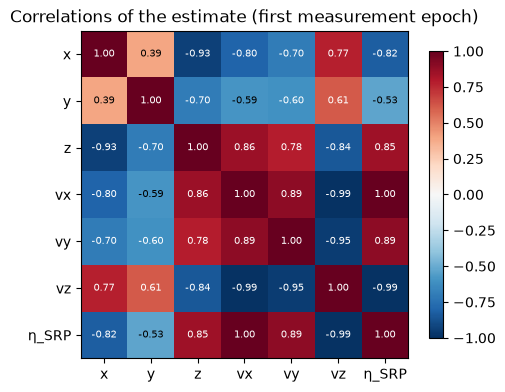

In [6]:
P_eta = solution_eta.covariance_est[0]
correlation = P_eta / np.sqrt(np.outer(P_eta.diagonal(), P_eta.diagonal()))
labels = ["x", "y", "z", "vx", "vy", "vz", "η_SRP"]

fig, ax = plt.subplots(figsize=(5, 4.2))
image = ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set(xticks=range(7), yticks=range(7), xticklabels=labels, yticklabels=labels,
       title="Correlations of the estimate (first measurement epoch)")
for (row, col), value in np.ndenumerate(correlation):
    ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=7,
            color="white" if abs(value) > 0.6 else "black")
fig.colorbar(image, ax=ax, shrink=0.8)
plt.tight_layout()

$\eta_\text{SRP}$ is almost perfectly correlated with the initial velocity (|ρ| ≈ 0.99 or more with $v_x$ and $v_z$). SRP is a small, nearly constant acceleration directed away from the Sun, and over a week a change in its size bends the trajectory almost the way a change in the initial velocity would. The data tell the two apart only through the small difference between those two effects, so estimating $\eta_\text{SRP}$ also loosens the velocity, and through it the position. A strong correlation like this is not a problem in itself: the filter still recovers $\eta_\text{SRP}$ to ±0.025, about 3%. But it is what the extra uncertainty is made of.

## 3. Consider parameters

Sometimes a parameter should not be estimated, for example because it is poorly observable from a short arc or because its value is fixed by an external calibration, yet its uncertainty is real. A **consider** parameter (Schmidt) keeps its a-priori value but propagates its uncertainty into the covariance of the estimated states. It is declared with `estimation="considered"`; here the scale factor is left at 1 with a 1σ uncertainty of 0.3:

In [7]:
%%capture fit_log
# 🔵 TODO: remove %%capture once filters and measurement models stop printing progress
state_consider = (scb.StateDefinition()
                  .position(reference_15, scb.ArrayWFrame(r_apriori, J2000))
                  .velocity(reference_15, scb.ArrayWFrame(v_apriori, J2000))
                  .param("eta_srp", reference_15, scb.ArrayWFrame(scb.ArrayWUnits([1.0], None), J2000),
                         estimation="considered", dynamics="static"))
P0_consider = scb.CovarianceMatrix(sigma_apriori + [scb.ArrayWUnits(0.3, None)], epochs[0], from_list=True)

srifb_consider = scb.SRIFB(propagator=reference_propagator(reference_15, state_consider), measurements=tracking,
                           settings=scb.FilterSettings(initial_covariance=P0_consider),
                           traj_name="consider.bsp", traj_dir=str(out))
solution_consider, _, _ = srifb_consider.fit(traj_name="consider.bsp", traj_dir=str(out), convergence_threshold=1e-5)

In [8]:
dr = solution_consider.state_est[0, :3] - x_true_first[:3]
sigma_r_consider = sum(solution_consider.covariance_consider[0].diagonal()[:3]) ** 0.5
print(f"η_SRP kept at {solution_consider.state_est[0, 6]:.1f}")
print(f"position error {(dr @ dr) ** 0.5:.1f} km, consider 1σ {sigma_r_consider:.1f} km "
      f"→ {(dr @ dr) ** 0.5 / sigma_r_consider:.2f} σ")

η_SRP kept at 1.0
position error 21.9 km, consider 1σ 24.4 km → 0.90 σ


/Users/andrealopez/Documents/Research/scarabaeus/src/scarabaeus/timeAndFrame/SpiceManager.py:1440: RuntimeWarning: Multiple matching JSON files found. Using most recently modified file: consider_it2_parameters.json
  warnings.warn(


<div style="border-left:4px solid #dc2626; background:rgba(220,38,38,0.12); padding:6px 10px; border-radius:4px">
🔴 <b>FIX:</b> In runs with consider parameters, <code>solution.covariance_est</code> (the data-noise-only covariance) has small negative velocity variances and is not positive semi-definite. <code>covariance_consider</code> is consistent with the actual errors and is used below.
</div>

The estimate is the same as in section 1, since $\eta_\text{SRP}$ was not adjusted, but the covariance is now honest about it: the 22 km error is within the consider uncertainty. The three approaches side by side, over the tracking week and three days past it. `propagate_state_covariance` maps each solution to any epoch, including the consider covariance when there is one:

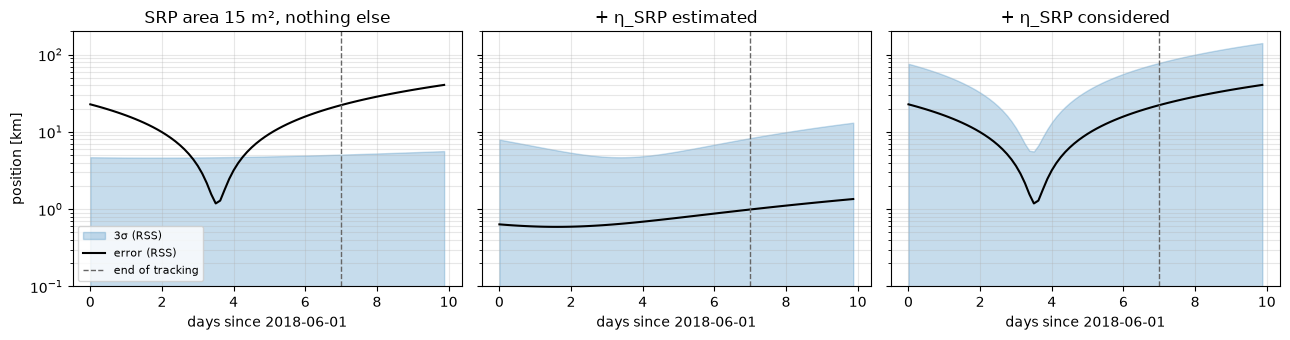

In [9]:
t_compare = scb.EpochArray.interval(
    scb.SpiceManager.utc2et("2018-06-01T00:00:00"),
    scb.SpiceManager.utc2et("2018-06-11T00:00:00"),
    dt=scb.ArrayWUnits(180, minute),
    sys="TDB",
)
# TODO(draft): get_state takes one epoch at a time; replace the loop once it accepts an EpochArray
r_true = np.array([orex.get_state(t, reference_frame="J2000", origin="SUN").quantity.values[:3] for t in t_compare])
t_days = (t_compare - epochs[0]).convert_to(day).values

runs = {
    "SRP area 15 m², nothing else": solution_wrong,
    "+ η_SRP estimated": solution_eta,
    "+ η_SRP considered": solution_consider,
}
# 🔵 TODO: use Plotting.plot_compare_state_error_norm once it draws one σ band per solution (scb_suggestions.md 6.71)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for a, (label, solution) in zip(ax, runs.items()):
    predicted = solution.propagate_state_covariance(t_compare)
    error = np.linalg.norm(np.array([state.values0.values[:3] for state, _ in predicted]) - r_true, axis=1)
    sigma3 = 3 * np.sqrt([np.trace(P[:3, :3]) for _, P in predicted])
    a.fill_between(t_days, 1e-2, sigma3, color="C0", alpha=0.25, label="3σ (RSS)")
    a.plot(t_days, error, "k", label="error (RSS)")
    a.axvline(7, color="0.4", ls="--", lw=1, label="end of tracking")
    a.set(title=label, xlabel="days since 2018-06-01", yscale="log", ylim=(0.1, 200))
    a.grid(alpha=0.3, which="both")
ax[0].set(ylabel="position [km]")
ax[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()

Ignoring the error, the estimate is 22 km off at the start of the arc and about 40 km off by June 11, against a 3σ of about 5 km. The error passes close to zero in the middle of the week, where the fit balances the wrong SRP acceleration across the arc; that is also why the residuals barely show it. Estimating $\eta_\text{SRP}$ keeps the error near 1 km and inside the bounds, three days into the prediction included. Considering it leaves the estimate exactly as wrong as in the first panel, but the consider covariance grows with the error and covers it everywhere, at the price of a 3σ of up to about 150 km.

At the first measurement epoch:

| Filter model | Position error | 1σ | Error / σ |
|---|---|---|---|
| SRP area 15 m², nothing else | ~22 km | ~1.6 km | ~14 |
| + $\eta_\text{SRP}$ estimated | sub-km | ~2.6 km | < 1 |
| + $\eta_\text{SRP}$ considered | ~22 km | ~24 km (consider) | < 1 |

Estimating corrects the state; considering only makes the uncertainty realistic. Considering is the right choice when estimating would fit noise, or when the parameter is not the filter's to adjust.

## Summary

| Concept | Scarabaeus API |
|---|---|
| SRP scale factor | `StateDefinition.param("eta_srp", spacecraft, value, estimation="estimated", dynamics="static")` |
| A-priori for parameters | extra σ entries in `CovarianceMatrix([...], epoch, from_list=True)` |
| Consider parameters | `estimation="considered"`, `SolutionOD.covariance_consider` |
| Correlations of the estimate | `SolutionOD.covariance_est` (estimated parameters included) |
| Comparing solutions in and past the arc | `SolutionOD.propagate_state_covariance(epochs)` (includes the consider covariance) |

**Next:** [9. Tracking data II: real DSN data](09_real_dsn_data.ipynb) replaces the simulated measurements with the real OSIRIS-REx tracking pass from June 8, 2018, edits its outliers, and estimates a ranging bias as another parameter.